# E-Commerce Sales & Customer Analysis
### Business Intelligence Report

**Objective:** Analyze transaction, product, customer, and sales behavior to identify actionable opportunities for improving revenue, customer retention, and inventory decisions.

**Data source:** E-commerce transaction dataset used in this notebook.


## استعدعاء المكتبات

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

##تحميل البيانات

In [89]:

import os
if not os.environ.get('KAGGLE_API_TOKEN'):
    print('KAGGLE_API_TOKEN is not set. If data.csv already exists, you can continue; otherwise set the token locally.')
!kaggle datasets download -d carrie1/ecommerce-data -p . --unzip


KAGGLE_API_TOKEN is not set. If data.csv already exists, you can continue; otherwise set the token locally.
Dataset URL: https://www.kaggle.com/datasets/carrie1/ecommerce-data
License(s): unknown
100% 7.20M/7.20M [00:00<00:00, 208MB/s]



## استعلام عن عدد الفواتير و محتويات البيانات

In [90]:
df = pd.read_csv('data.csv', encoding='ISO-8859-1')

print("SHAPE:", df.shape)
df.head()

SHAPE: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


##معالجه و تنضيف البيانات

In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [92]:
df.shape
df = df.dropna()
df.shape

(406829, 8)

In [93]:
print("عدد المكررات قبل الحذف:", df.duplicated().sum())
df=df.drop_duplicates()
print("عدد المكررات بعد الحذف:", df.duplicated().sum())

عدد المكررات قبل الحذف: 5225
عدد المكررات بعد الحذف: 0


In [94]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['CustomerID'] = df['CustomerID'].astype(int)

In [95]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,401604.000000,401604,401604.000000,401604.000000
mean,12.183273,2011-07-10 12:08:23.848567552,3.474064,15281.160818
min,-80995.000000,2010-12-01 08:26:00,0.000000,12346.000000
25%,2.000000,2011-04-06 15:02:00,1.250000,13939.000000
50%,5.000000,2011-07-29 15:40:00,1.950000,15145.000000
75%,12.000000,2011-10-20 11:58:30,3.750000,16784.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,250.283037,NaN,69.764035,1714.006089


###يوضح هذا المخطط أن معظم العملاء يشترون كميات قليلة من المنتج في كل عملية شراء، بينما توجد نسبة أقل من العملاء تشتري كميات كبيرة.

### ولزيادة عدد العملاء الذين يشترون كميات أكبر، يمكن تقديم خصومات وعروض خاصة عند شراء كميات كبيرة، بالإضافة إلى تصميم حملات تسويقية تستهدف هذه الفئة وتشجع بقية العملاء على زيادة كمية مشترياتهم، مما قد يساهم في زيادة المبيعات والأرباح.

##يوضح  المخطط التاني توزيع عدد المنتجات المباعة في كل فاتورة، مع التركيز على الفواتير التي تحتوي على أقل من 200 قطعة، مما يساعد على فهم سلوك العملاء بشكل أكثر تفصيلًا وتحديد الكميات الأكثر شيوعًا في عمليات الشراء.

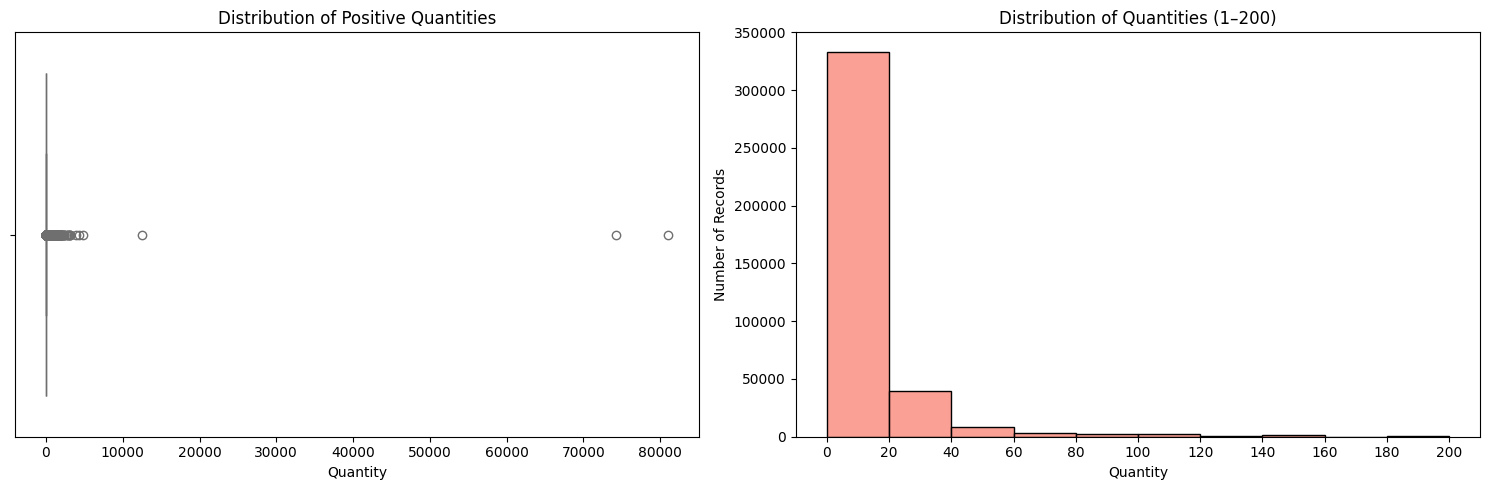

In [96]:
# Create a copy to preserve the original data
sales_df = df.copy()
positive_sales = sales_df[sales_df['Quantity'] > 0]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    x=positive_sales['Quantity'],
    ax=axes[0],
    color='skyblue'
)
axes[0].set_title('Distribution of Positive Quantities')
axes[0].set_xlabel('Quantity')

small_quantities = positive_sales.loc[
    positive_sales['Quantity'].between(1, 200), 'Quantity'
]

sns.histplot(
    x=small_quantities,
    bins=np.arange(0, 201, 20),
    ax=axes[1],
    color='salmon',
    edgecolor='black'
)
axes[1].set_title('Distribution of Quantities (1–200)')
axes[1].set_xlabel('Quantity')
axes[1].set_ylabel('Number of Records')
axes[1].set_xticks(np.arange(0, 201, 20))

plt.tight_layout()
plt.show()



### من المخطط يتضح أن السلع ذات السعر المنخفض هي الأكثر مبيعًا." ولذا يمكن التركيز على توفيرها بشكل أكبر. أما السلع مرتفعة السعر، فيمكن دعم مبيعاتها بعروض خاصة أو حملات تسويقية."

###يوضح  المخطط التاني توزيع المنتجات المباعة التي يقل سعرها عن 200، مما يساعدنا على فهم أنماط شراء العملاء لهذه الفئة السعرية وتحديد المنتجات الأكثر مبيعًا. وبناءً على هذه النتائج، يمكننا التركيز على توفير المنتجات التي تحظى بطلب مرتفع، مع دراسة فرص زيادة مبيعاتها من خلال العروض الترويجية والتسويق المستهدف.

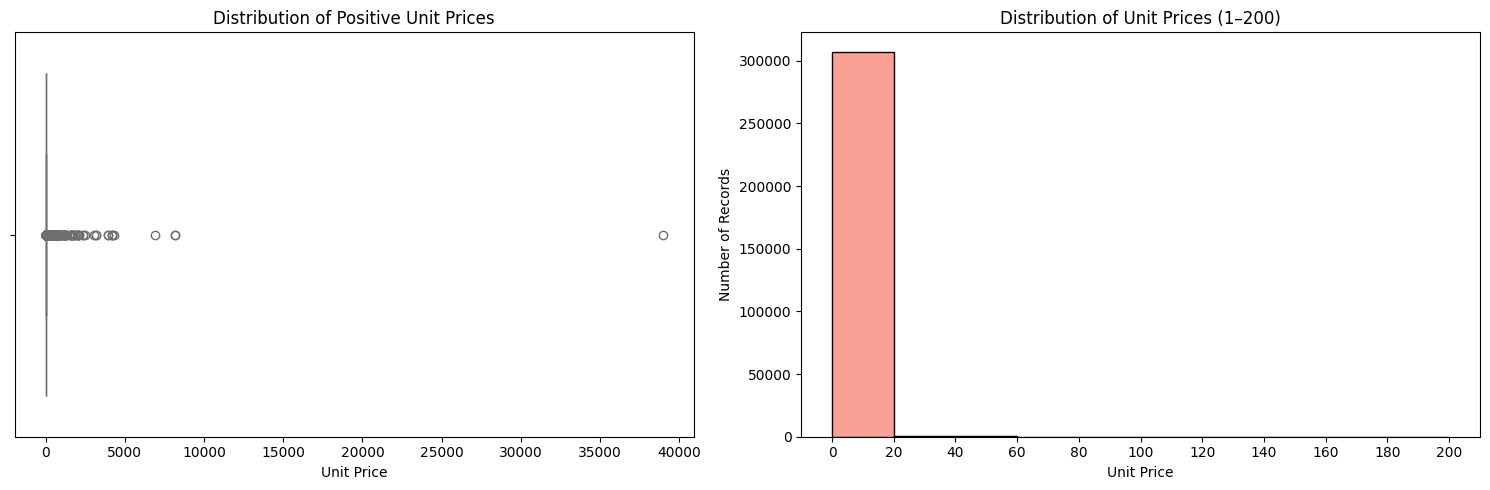

In [97]:

sales_df = df.copy()
positive_prices = sales_df[sales_df['UnitPrice'] > 0]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    x=positive_prices['UnitPrice'],
    ax=axes[0],
    color='skyblue'
)

axes[0].set_title('Distribution of Positive Unit Prices')
axes[0].set_xlabel('Unit Price')


prices_range = positive_prices.loc[
    positive_prices['UnitPrice'].between(1, 200),
    'UnitPrice'
]

sns.histplot(
    x=prices_range,
    bins=np.arange(0, 201, 20),
    ax=axes[1],
    color='salmon',
    edgecolor='black'
)

axes[1].set_title('Distribution of Unit Prices (1–200)')
axes[1].set_xlabel('Unit Price')
axes[1].set_ylabel('Number of Records')
axes[1].set_xticks(np.arange(0, 201, 20))

plt.tight_layout()
plt.show()

###يوضح هذا المخطط توزيع المنتجات المباعة التي يقل سعرها عن 200، مما يساعدنا على فهم أنماط شراء العملاء لهذه الفئة السعرية وتحديد المنتجات الأكثر مبيعًا. وبناءً على هذه النتائج، يمكننا التركيز على توفير المنتجات التي تحظى بطلب مرتفع، مع دراسة فرص زيادة مبيعاتها من خلال العروض الترويجية والتسويق المستهدف.


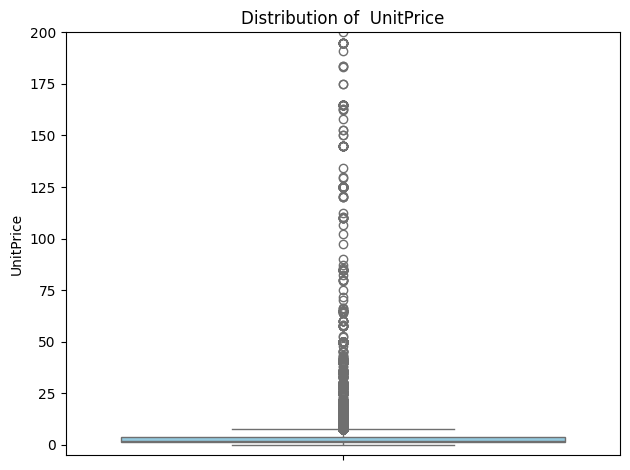

In [147]:

sns.boxplot(positive_prices['UnitPrice'] ,color='skyblue')
plt.title('Distribution of  UnitPrice')
plt.ylim(-5, 200)
plt.tight_layout()
plt.show()

### إجمالي قيمة المنتج في الفاتورة الواحدة، ويتم حسابها بضرب الكمية في سعر الوحدة

In [99]:
df['LineTotal'] = df['Quantity'] * df['UnitPrice']

# 1. Business Overview

This section summarizes the store's performance using the cleaned transaction data.

**Important:** `LineTotal = Quantity × UnitPrice` represents sales transaction value. It is **not profit**, because the dataset does not contain product cost or margin. Negative quantities are treated as returns/cancellations and therefore reduce net sales.


In [100]:
# Executive KPIs
total_revenue = df['LineTotal'].sum()
total_orders = df['InvoiceNo'].nunique()
total_customers = df['CustomerID'].nunique()
total_products = df['StockCode'].nunique()
avg_order_value = total_revenue / total_orders if total_orders else 0
return_value = df.loc[df['Quantity'] < 0, 'LineTotal'].sum()
return_lines = (df['Quantity'] < 0).sum()

kpis = pd.DataFrame({
    'KPI': ['Net Sales Value', 'Orders', 'Customers', 'Products', 'Average Order Value', 'Return/Cancellation Value'],
    'Value': [total_revenue, total_orders, total_customers, total_products, avg_order_value, return_value]
})
kpis


,KPI,Value
0,Net Sales Value,8.278519e+06
1,Orders,2.218600e+04
2,Customers,4.371000e+03
3,Products,3.684000e+03
4,Average Order Value,3.731416e+02
5,Return/Cancellation Value,-6.086895e+05


### How to read the KPIs
- **Net Sales Value:** sum of `LineTotal`, so returns/cancellations with negative quantities reduce the total.
- **Average Order Value (AOV):** total sales value divided by unique invoices.
- **Return/Cancellation Value:** the total negative sales value; this is useful for monitoring return activity.


# 2. أداء المبيعات بمرور الوقت

يساعد تحليل الوقت المتجرَ على تحديد أنماط النمو أو التراجع، وكذلك الفترات التي قد تتطلب عروضاً ترويجية، أو توفير طاقم عمل، أو تخطيطاً للمخزون.


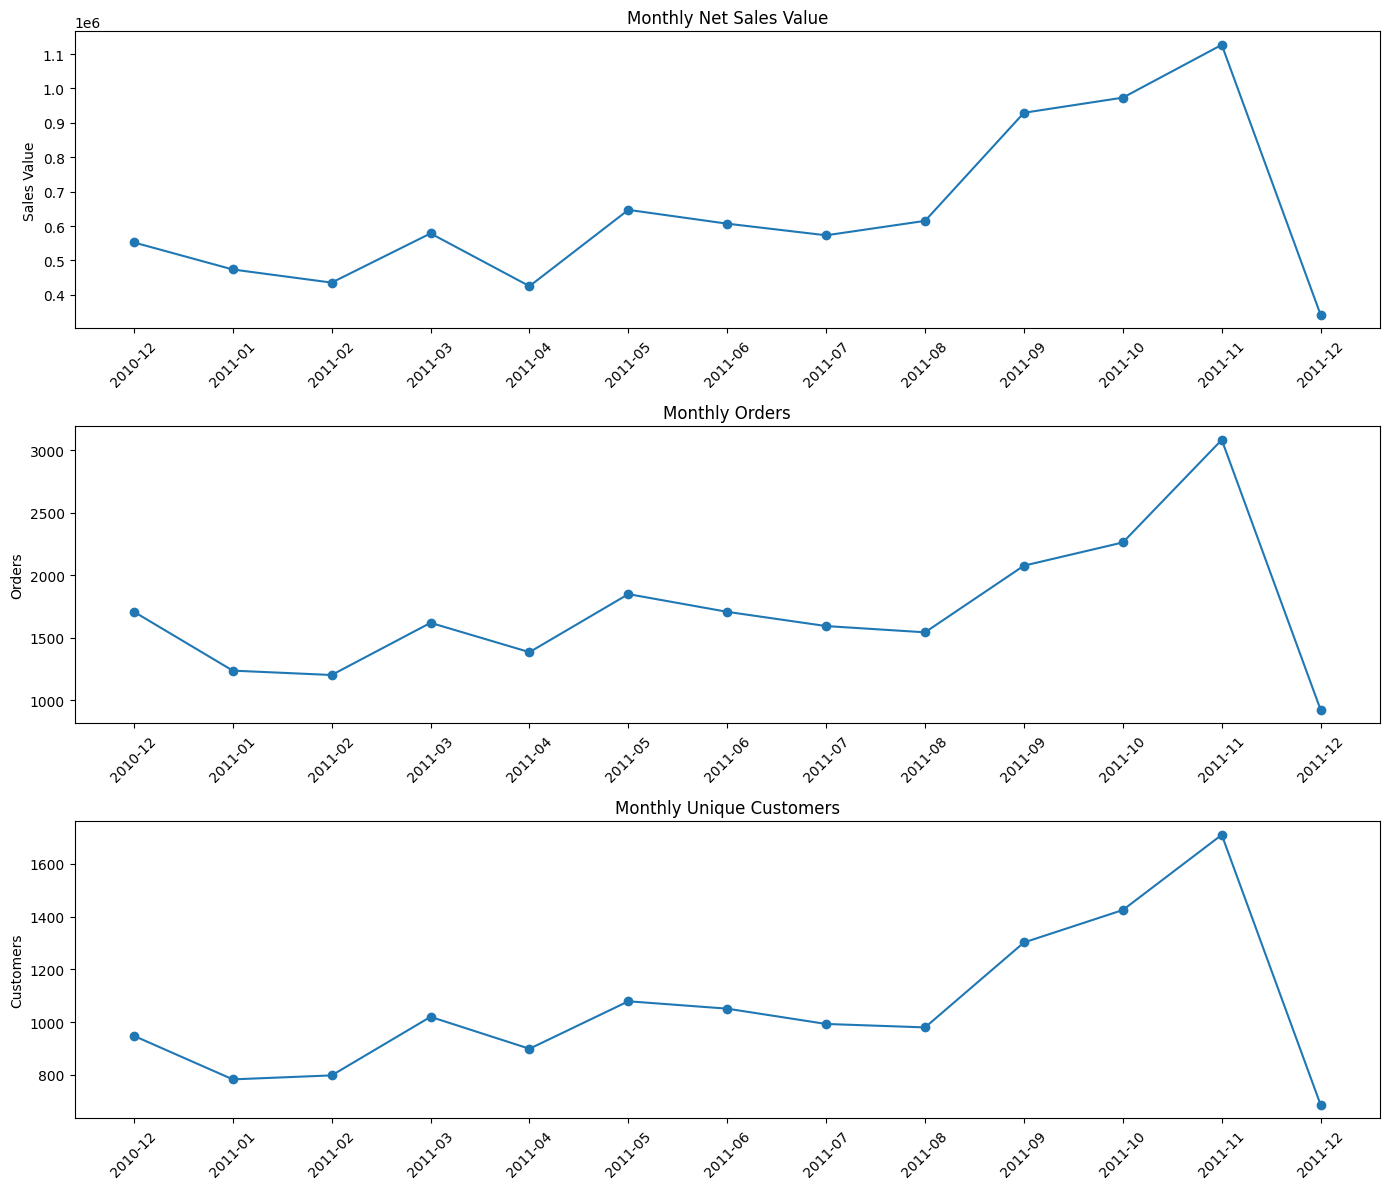

,Month,Revenue,Orders,Customers
0,2010-12,552372.860,1708,948
1,2011-01,473731.900,1236,783
2,2011-02,435534.070,1201,798
3,2011-03,578576.210,1619,1020
4,2011-04,425222.671,1384,899
5,2011-05,647011.670,1849,1079
6,2011-06,606862.520,1707,1051
7,2011-07,573112.321,1593,993
8,2011-08,615078.090,1543,980
9,2011-09,929356.232,2077,1302


In [151]:
monthly_sales = (
    df.assign(Month=df['InvoiceDate'].dt.to_period('M').astype(str))
      .groupby('Month', as_index=False)
      .agg(Revenue=('LineTotal','sum'), Orders=('InvoiceNo','nunique'), Customers=('CustomerID','nunique'))
)

fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes[0].plot(monthly_sales['Month'], monthly_sales['Revenue'], marker='o')
axes[0].set_title('Monthly Net Sales Value')
axes[0].set_ylabel('Sales Value')
axes[1].plot(monthly_sales['Month'], monthly_sales['Orders'], marker='o')
axes[1].set_title('Monthly Orders')
axes[1].set_ylabel('Orders')
axes[2].plot(monthly_sales['Month'], monthly_sales['Customers'], marker='o')
axes[2].set_title('Monthly Unique Customers')
axes[2].set_ylabel('Customers')
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('3.png', dpi=300, bbox_inches='tight')
plt.show()

monthly_sales


# 3. الأداء الجغرافي

يُظهر التحليل على مستوى الدولة المناطق التي يحقق فيها المتجر أعلى معدلات المبيعات، وتلك التي قد تتوفر فيها فرص لاكتساب العملاء أو الاحتفاظ بهم.

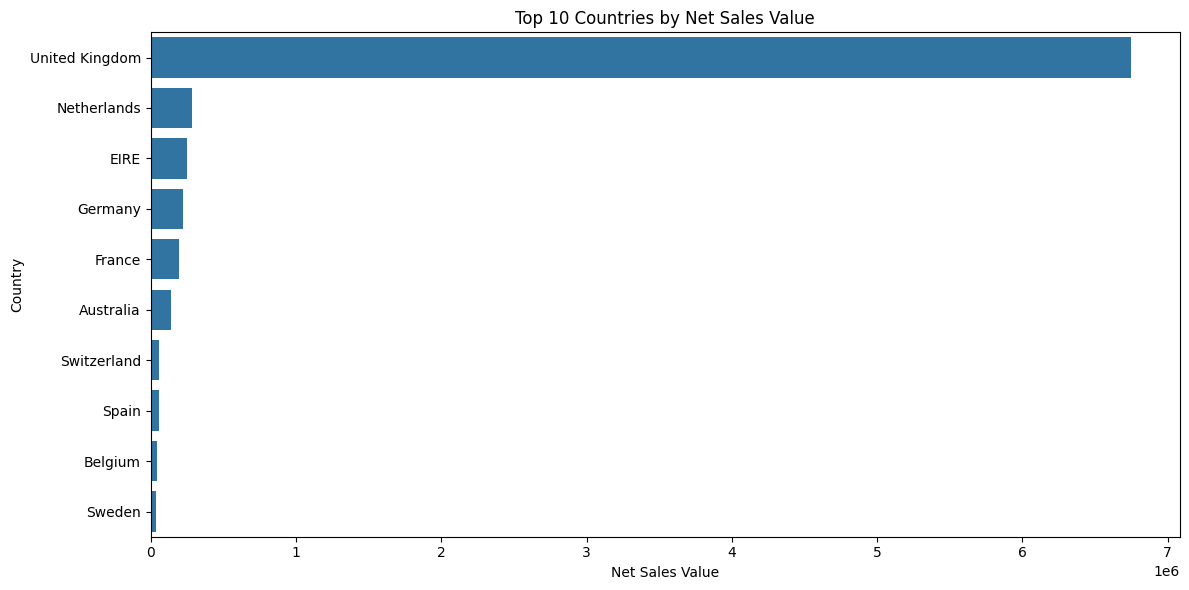

,Country,Revenue,Orders,Customers
35,United Kingdom,6747156.154,19854,3949
23,Netherlands,284661.540,100,9
10,EIRE,250001.780,319,3
14,Germany,221509.470,603,95
13,France,196626.050,458,87
0,Australia,137009.770,69,9
32,Switzerland,55739.400,71,21
30,Spain,54756.030,105,31
3,Belgium,40910.960,119,25
31,Sweden,36585.410,46,8


In [150]:
country_sales = (
    df.groupby('Country', as_index=False)
      .agg(Revenue=('LineTotal','sum'), Orders=('InvoiceNo','nunique'), Customers=('CustomerID','nunique'))
      .sort_values('Revenue', ascending=False)
)

top10_countries = country_sales.head(10)
plt.figure(figsize=(12,6))
sns.barplot(data=top10_countries, x='Revenue', y='Country')
plt.title('Top 10 Countries by Net Sales Value')
plt.xlabel('Net Sales Value')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig('2.png', dpi=300, bbox_inches='tight')
plt.show()

top10_countries


# 4.  مساهمة المنتج
لا يعكس ترتيب المنتجات حسب الإيرادات وحدها مدى أهمية المنتج بالنسبة للنشاط التجاري ككل؛ إذ تُسهّل نسبة المساهمة الموضحة أدناه عملية تحديد الأولويات


### نقوم ب حساب ل كل منتج :الكميه المباعه و المبلغ المدفوع و عدد الفاوتير الموجود بيها المنتج و عدد العملاء الذين اشتروا المنتج

In [103]:
product_df = df.groupby('Description').agg(
    Total_Quantity=('Quantity', 'sum'),
    Total_Revenue=('LineTotal', 'sum'),
    Orders_Count=('InvoiceNo', 'nunique'),
    Unique_Customers=('CustomerID', 'nunique'),
    Avg_Price=('UnitPrice', 'mean')
).reset_index()


In [104]:
product_contribution = product_df.copy()
product_contribution['Revenue_Contribution_%'] = (
    product_contribution['Total_Revenue'] / product_contribution['Total_Revenue'].sum() * 100
)
product_contribution = product_contribution.sort_values('Total_Revenue', ascending=False)

product_contribution[['Description','Total_Revenue','Revenue_Contribution_%','Orders_Count','Unique_Customers']].head(5)


,Description,Total_Revenue,Revenue_Contribution_%,Orders_Count,Unique_Customers
2780,REGENCY CAKESTAND 3 TIER,132567.70,1.601346,1883,887
3716,WHITE HANGING HEART T-LIGHT HOLDER,93767.80,1.132664,2013,858
1771,JUMBO BAG RED RETROSPOT,83056.52,1.003277,1643,636
2355,PARTY BUNTING,67628.43,0.816915,1398,708
2624,POSTAGE,66710.24,0.805823,1194,379


### عدد المنتجات 3877 منتج

In [105]:
product_df.shape

(3896, 6)

In [106]:
product_df.describe()

,Total_Quantity,Total_Revenue,Orders_Count,Unique_Customers,Avg_Price
count,3896.000000,3896.000000,3896.000000,3896.000000,3896.000000
mean,1252.301591,2124.876649,101.782084,69.082906,3.994525
std,2782.456263,5403.630535,158.046057,89.652500,19.687962
min,-1475.000000,-58745.460000,1.000000,1.000000,0.001000
25%,51.000000,107.070000,10.000000,9.000000,1.019722
50%,330.500000,558.355000,43.000000,36.000000,1.950000
75%,1287.000000,1930.900000,127.000000,94.000000,3.886952
max,53119.000000,132567.700000,2013.000000,887.000000,744.147500


### اكتر منتاجات مباعين ب كميات

In [107]:
product_df_sorted_by_Total_Quantity = product_df.sort_values(by='Total_Quantity', ascending=False)
product_df_sorted_by_Total_Quantity.head(5)

,Description,Total_Quantity,Total_Revenue,Orders_Count,Unique_Customers,Avg_Price
3805,WORLD WAR 2 GLIDERS ASSTD DESIGNS,53119,13304.49,477,307,0.292034
1771,JUMBO BAG RED RETROSPOT,44963,83056.52,1643,636,2.013140
217,ASSORTED COLOUR BIRD ORNAMENT,35215,56331.91,1385,679,1.680776
3716,WHITE HANGING HEART T-LIGHT HOLDER,34128,93767.80,2013,858,2.891020
2279,PACK OF 72 RETROSPOT CAKE CASES,33386,16235.30,1041,636,0.547957


### اكتر المنتجات المباعه لكن لاحظت ان
####(PAPER CRAFT , LITTLE BIRDIE ) هو اكتر كميه مباعه لكنه كان مره واحده من عميل واحد

/tmp/ipykernel_2088/969864740.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'WORLD WAR 2 GLIDERS ASSTD DESIGNS'),
  Text(1, 0, 'JUMBO BAG RED RETROSPOT'),
  Text(2, 0, 'ASSORTED COLOUR BIRD ORNAMENT'),
  Text(3, 0, 'WHITE HANGING HEART T-LIGHT HOLDER'),
  Text(4, 0, 'PACK OF 72 RETROSPOT CAKE CASES'),
  Text(5, 0, 'POPCORN HOLDER'),
  Text(6, 0, 'RABBIT NIGHT LIGHT'),
  Text(7, 0, 'MINI PAINT SET VINTAGE '),
  Text(8, 0, 'PACK OF 12 LONDON TISSUES '),
  Text(9, 0, 'PACK OF 60 PINK PAISLEY CAKE CASES'),
  Text(10, 0, 'BROCADE RING PURSE '),
  Text(11, 0, 'VICTORIAN GLASS HANGING T-LIGHT'),
  Text(12, 0, 'ASSORTED COLOURS SILK FAN'),
  Text(13, 0, 'RED  HARMONICA IN BOX '),
  Text(14, 0, 'JUMBO BAG PINK POLKADOT'),
  Text(15, 0, 'SMALL POPCORN HOLDER'),
  Text(16, 0, '60 TEATIME FAIRY CAKE CASES'),
  Text(17, 0, 'LUNCH BAG RED RETROSPOT'),
  Text(18, 0, 'HEART OF WICKER SMALL'),
  Text(19, 0, 'JUMBO BAG STRAWBERRY')])

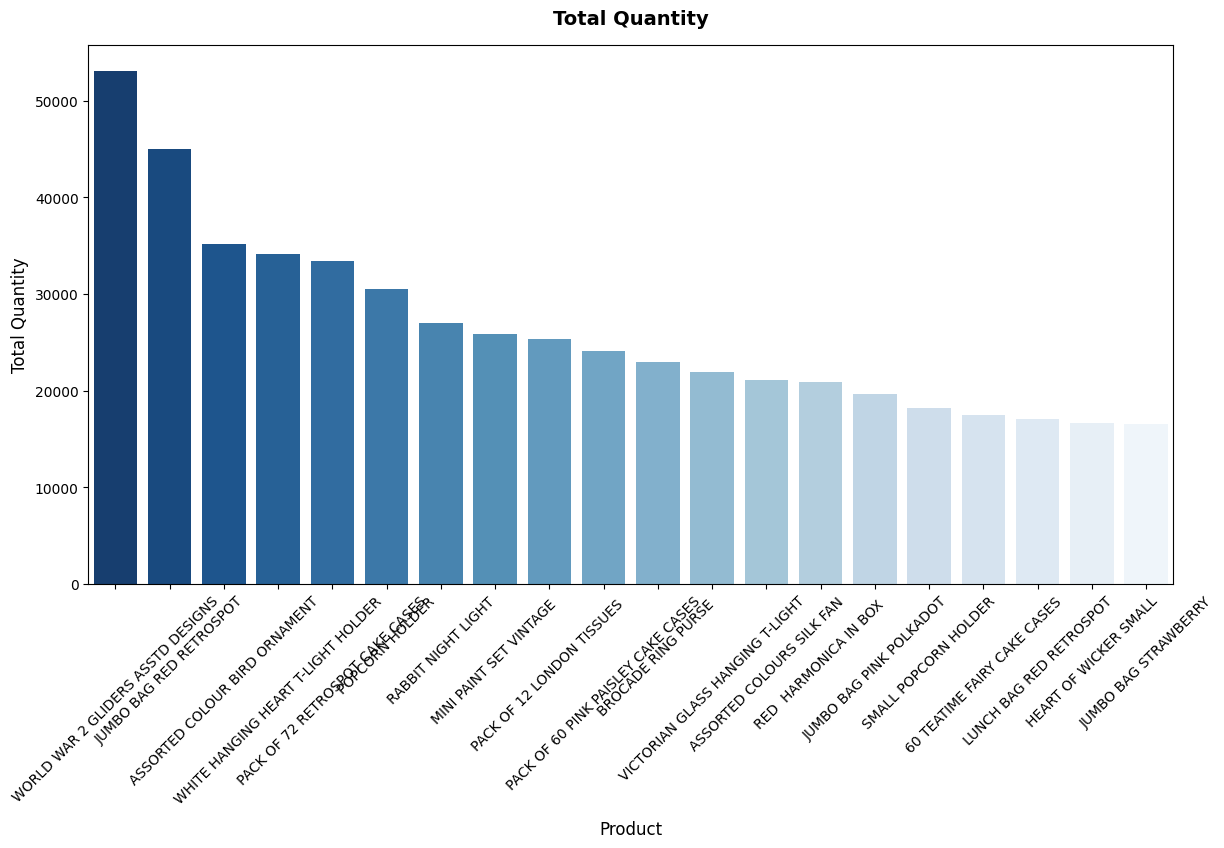

In [108]:
top_products = product_df.sort_values(by='Total_Quantity', ascending=False).head(20)
plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=top_products,
    x='Description',
    y='Total_Quantity',
    palette='Blues_r'
)

plt.title('Total Quantity', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Product', fontsize=12, labelpad=10)
plt.ylabel('Total Quantity', fontsize=12)
plt.xticks(rotation=45)

In [109]:
top_revenue_products = product_df.sort_values(by='Total_Revenue', ascending=False)
top_revenue_products.head(5)


,Description,Total_Quantity,Total_Revenue,Orders_Count,Unique_Customers,Avg_Price
2780,REGENCY CAKESTAND 3 TIER,11519,132567.70,1883,887,12.435077
3716,WHITE HANGING HEART T-LIGHT HOLDER,34128,93767.80,2013,858,2.891020
1771,JUMBO BAG RED RETROSPOT,44963,83056.52,1643,636,2.013140
2355,PARTY BUNTING,15011,67628.43,1398,708,4.874084
2624,POSTAGE,3002,66710.24,1194,379,37.888528


# أكثر المنتجات تحقيقاً للإيرادات

/tmp/ipykernel_2088/3303435020.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


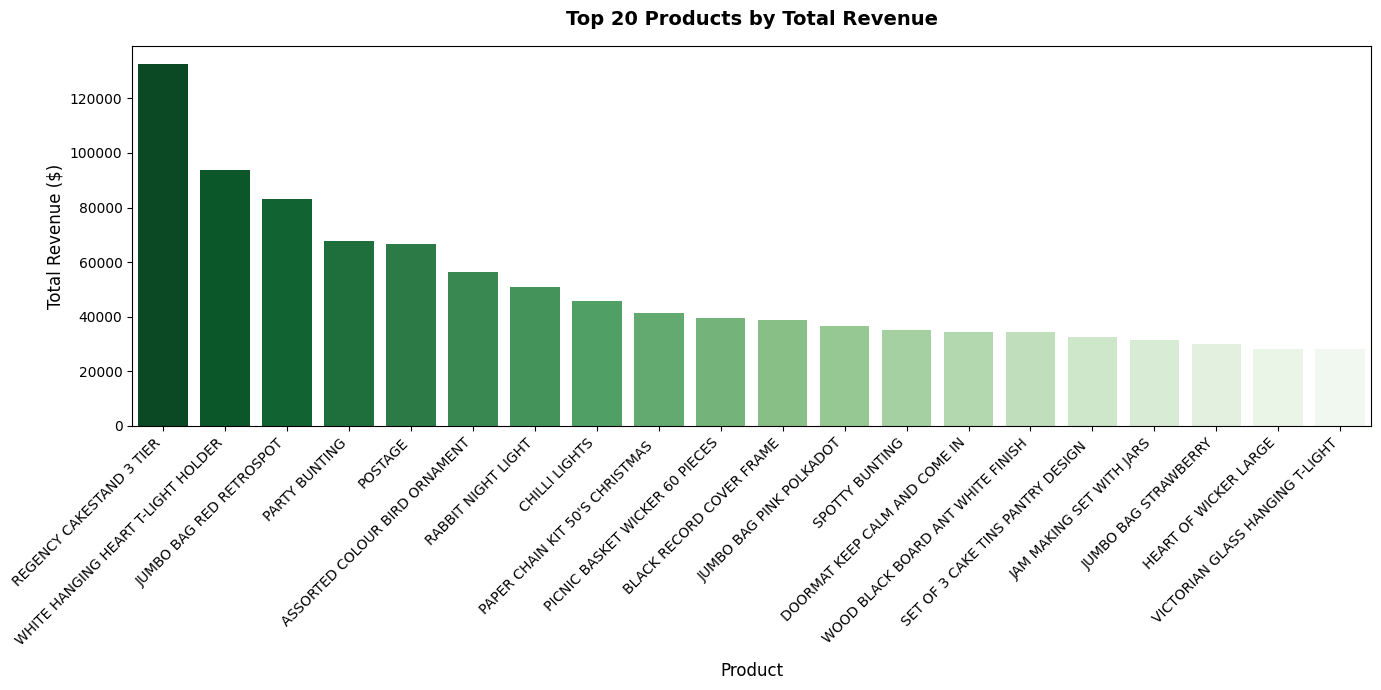

In [110]:
top_revenue_products = product_df.sort_values(by='Total_Revenue', ascending=False).head(20)

plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=top_revenue_products,
    x='Description',
    y='Total_Revenue',
    palette='Greens_r'
)

plt.title('Top 20 Products by Total Revenue', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Product', fontsize=12, labelpad=10)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

In [111]:
Least_orders_products = product_df.sort_values(by='Orders_Count', ascending=True)
Least_orders_products.head(5)

,Description,Total_Quantity,Total_Revenue,Orders_Count,Unique_Customers,Avg_Price
3562,VINTAGE BEAD PINK JEWEL STAND,1,4.95,1,1,4.95
3885,ZINC PLANT POT HOLDER,8,23.12,1,1,2.89
3572,VINTAGE BLUE TINSEL REEL,2,0.84,1,1,0.42
1720,IVORY SHELL HEART EARRINGS,2,5.10,1,1,2.55
1731,JADE CRYSTAL+GLASS BRACELET,1,4.95,1,1,4.95


In [112]:
Least_Total_Quantity_products = product_df.sort_values(by='Total_Quantity', ascending=True)
Least_Total_Quantity_products.head(5)

,Description,Total_Quantity,Total_Revenue,Orders_Count,Unique_Customers,Avg_Price
2880,ROTATING SILVER ANGELS T-LIGHT HLDR,-1475,17255.62,308,193,2.598731
1066,Discount,-1194,-5696.22,65,24,72.484545
245,ASSORTED TUTTI FRUTTI ROUND BOX,-24,-39.60,1,1,1.650000
882,CRUK Commission,-16,-7933.43,16,1,495.839375
2537,PINK POODLE HANGING DECORATION,-12,-4.56,1,1,0.380000


In [113]:
def classify_product(row):
    if row['Total_Quantity'] < 55 and row['Orders_Count'] < 10:
        return 'Low Performing (Slow Moving)'
    elif row['Total_Quantity'] >= 1321:
        return 'Top Performing (Best Seller)'
    else:
        return 'Moderate Performing'


product_df['Performance_Category'] = product_df.apply(classify_product, axis=1)


low_performing_df = product_df[product_df['Performance_Category'] == 'Low Performing (Slow Moving)']

print(f"إجمالي عدد المنتجات ضعيفة الأداء: {len(low_performing_df)}")
low_performing_df.head()

إجمالي عدد المنتجات ضعيفة الأداء: 798


,Description,Total_Quantity,Total_Revenue,Orders_Count,Unique_Customers,Avg_Price,Performance_Category
4,I LOVE LONDON MINI RUCKSACK,1,4.15,1,1,4.15,Low Performing (Slow Moving)
10,TOADSTOOL BEDSIDE LIGHT,2,17.90,1,1,8.95,Low Performing (Slow Moving)
16,12 HANGING EGGS HAND PAINTED,40,83.20,7,7,2.08,Low Performing (Slow Moving)
29,15 PINK FLUFFY CHICKS IN BOX,10,29.50,7,7,2.95,Low Performing (Slow Moving)
31,16 PC CUTLERY SET PANTRY DESIGN,4,63.80,1,1,15.95,Low Performing (Slow Moving)


In [114]:
top_orders_products = product_df.sort_values(by='Orders_Count', ascending=False)
top_orders_products.head(5)

,Description,Total_Quantity,Total_Revenue,Orders_Count,Unique_Customers,Avg_Price,Performance_Category
3716,WHITE HANGING HEART T-LIGHT HOLDER,34128,93767.80,2013,858,2.891020,Top Performing (Best Seller)
2780,REGENCY CAKESTAND 3 TIER,11519,132567.70,1883,887,12.435077,Top Performing (Best Seller)
1771,JUMBO BAG RED RETROSPOT,44963,83056.52,1643,636,2.013140,Top Performing (Best Seller)
2355,PARTY BUNTING,15011,67628.43,1398,708,4.874084,Top Performing (Best Seller)
217,ASSORTED COLOUR BIRD ORNAMENT,35215,56331.91,1385,679,1.680776,Top Performing (Best Seller)


#أكثر المنتجات ظهوراً في الطلبات

/tmp/ipykernel_2088/3396336410.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


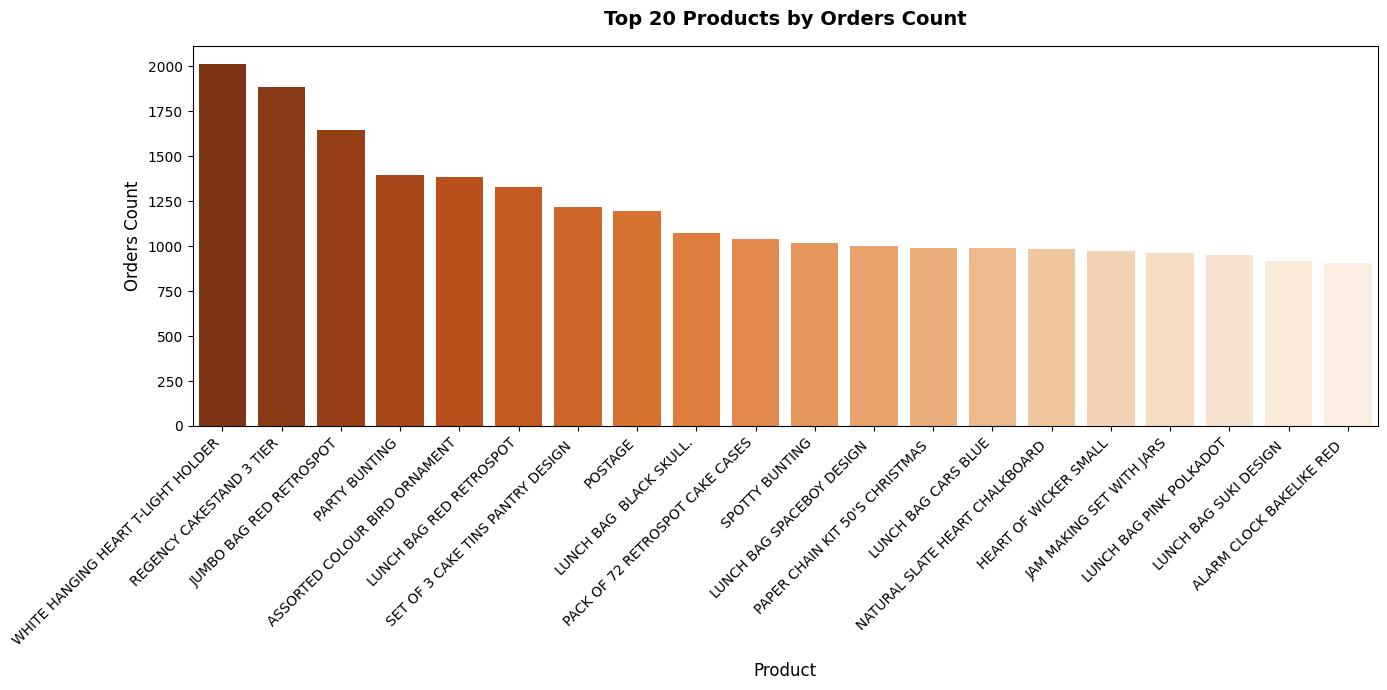

In [115]:
top_orders_products = product_df.sort_values(by='Orders_Count', ascending=False).head(20)

plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=top_orders_products,
    x='Description',
    y='Orders_Count',
    palette='Oranges_r'
)

plt.title('Top 20 Products by Orders Count', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Product', fontsize=12, labelpad=10)
plt.ylabel('Orders Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

#أكثر المنتجات جذباً لعملاء مختلفين

In [116]:
top_customers_products = product_df.sort_values(by='Unique_Customers', ascending=False)
top_customers_products.head(5)

,Description,Total_Quantity,Total_Revenue,Orders_Count,Unique_Customers,Avg_Price,Performance_Category
2780,REGENCY CAKESTAND 3 TIER,11519,132567.70,1883,887,12.435077,Top Performing (Best Seller)
3716,WHITE HANGING HEART T-LIGHT HOLDER,34128,93767.80,2013,858,2.891020,Top Performing (Best Seller)
2355,PARTY BUNTING,15011,67628.43,1398,708,4.874084,Top Performing (Best Seller)
217,ASSORTED COLOUR BIRD ORNAMENT,35215,56331.91,1385,679,1.680776,Top Performing (Best Seller)
3014,SET OF 3 CAKE TINS PANTRY DESIGN,6857,32573.15,1218,640,4.951136,Top Performing (Best Seller)


/tmp/ipykernel_2088/3947277543.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


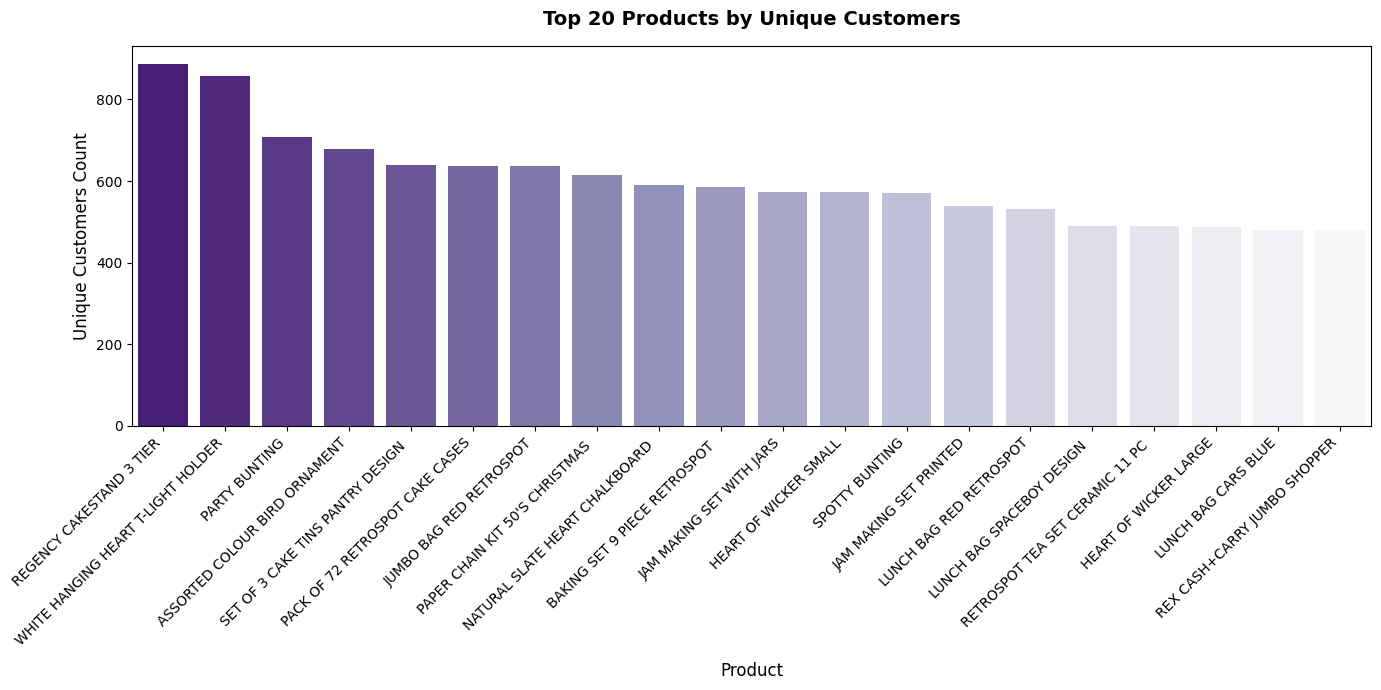

In [117]:

top_customers_products = product_df.sort_values(by='Unique_Customers', ascending=False).head(20)

plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=top_customers_products,
    x='Description',
    y='Unique_Customers',
    palette='Purples_r'
)

plt.title('Top 20 Products by Unique Customers', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Product', fontsize=12, labelpad=10)
plt.ylabel('Unique Customers Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

##المرتجعات

###عدد القطع المرتجعه و نسبتها

In [118]:

sales_df = df[df['Quantity'] > 0].copy()
returns_df = df[df['Quantity'] < 0].copy()


total_sold = sales_df['Quantity'].sum()
total_returned = returns_df['Quantity'].abs().sum()

return_rate = (total_returned / total_sold) * 100

print("Total Units Sold:", total_sold)
print("Total Units Returned:", total_returned)
print("Return Rate:", round(return_rate, 2), "%")


print("Negative Quantity Records:", len(returns_df))

Total Units Sold: 5152002
Total Units Returned: 273035
Return Rate: 5.3 %
Negative Quantity Records: 8872


In [139]:
top_returns = (
    returns_df.groupby('Description')['Quantity']
    .sum()
    .abs()
    .sort_values(ascending=False)
)
print(top_returns.shape)
top_returns.head(5)

(1945,)


,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,74494
ROTATING SILVER ANGELS T-LIGHT HLDR,9367
Manual,3995
FAIRY CAKE FLANNEL ASSORTED COLOUR,3150


##مخطط يوضح المنتجات المرتجعه

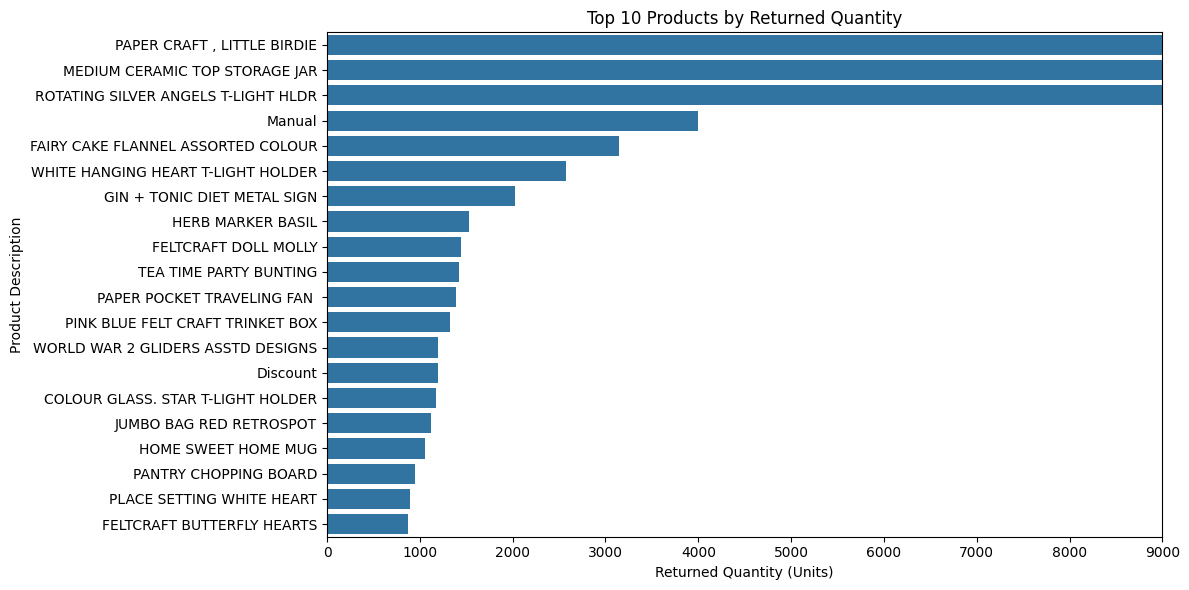

In [137]:
plt.figure(figsize=(12, 6))
top_returns = top_returns.head(20)
sns.barplot(x=top_returns.values, y=top_returns.index)

plt.title('Top 10 Products by Returned Quantity')
plt.xlabel('Returned Quantity (Units)')
plt.ylabel('Product Description')
plt.xlim(0, 9000)
plt.tight_layout()
plt.show()

## صافي المنتاجات المباعه

In [140]:
sales_by_product = (
    sales_df.dropna(subset=['Description'])
    .groupby('Description')['Quantity']
    .sum()
    .rename('Total Sold')
)

returns_by_product = (
    returns_df.dropna(subset=['Description'])
    .groupby('Description')['Quantity']
    .sum()
    .abs()
    .rename('Total Returned')
)

product_analysis = pd.concat(
    [sales_by_product, returns_by_product],
    axis=1
).fillna(0)

product_analysis['Net Quantity'] = (
    product_analysis['Total Sold']
    - product_analysis['Total Returned']
)

product_analysis['Return Rate (%)'] = (
    product_analysis['Total Returned']
    / product_analysis['Total Sold'].replace(0, np.nan)
    * 100
)

display(product_analysis.head())

,Total Sold,Total Returned,Net Quantity,Return Rate (%)
Description,,,,
4 PURPLE FLOCK DINNER CANDLES,138.0,0.0,138.0,0.000000
50'S CHRISTMAS GIFT BAG LARGE,1885.0,2.0,1883.0,0.106101
DOLLY GIRL BEAKER,2394.0,7.0,2387.0,0.292398
I LOVE LONDON MINI BACKPACK,359.0,0.0,359.0,0.000000
I LOVE LONDON MINI RUCKSACK,1.0,0.0,1.0,0.000000


In [146]:
top_net_sales = (
    product_analysis
    .sort_values('Net Quantity', ascending=False)
    .head(20)
)

display(top_net_sales)

,Total Sold,Total Returned,Net Quantity,Return Rate (%)
Description,,,,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319.0,1200.0,53119.0,2.209172
JUMBO BAG RED RETROSPOT,46078.0,1115.0,44963.0,2.419810
ASSORTED COLOUR BIRD ORNAMENT,35263.0,48.0,35215.0,0.136120
WHITE HANGING HEART T-LIGHT HOLDER,36706.0,2578.0,34128.0,7.023375
PACK OF 72 RETROSPOT CAKE CASES,33670.0,284.0,33386.0,0.843481
POPCORN HOLDER,30919.0,427.0,30492.0,1.381028
RABBIT NIGHT LIGHT,27153.0,108.0,27045.0,0.397746
MINI PAINT SET VINTAGE,26076.0,196.0,25880.0,0.751649
PACK OF 12 LONDON TISSUES,25329.0,24.0,25305.0,0.094753


##مخطط لأعلى  منتج من حيث صافي الكمية المباعة

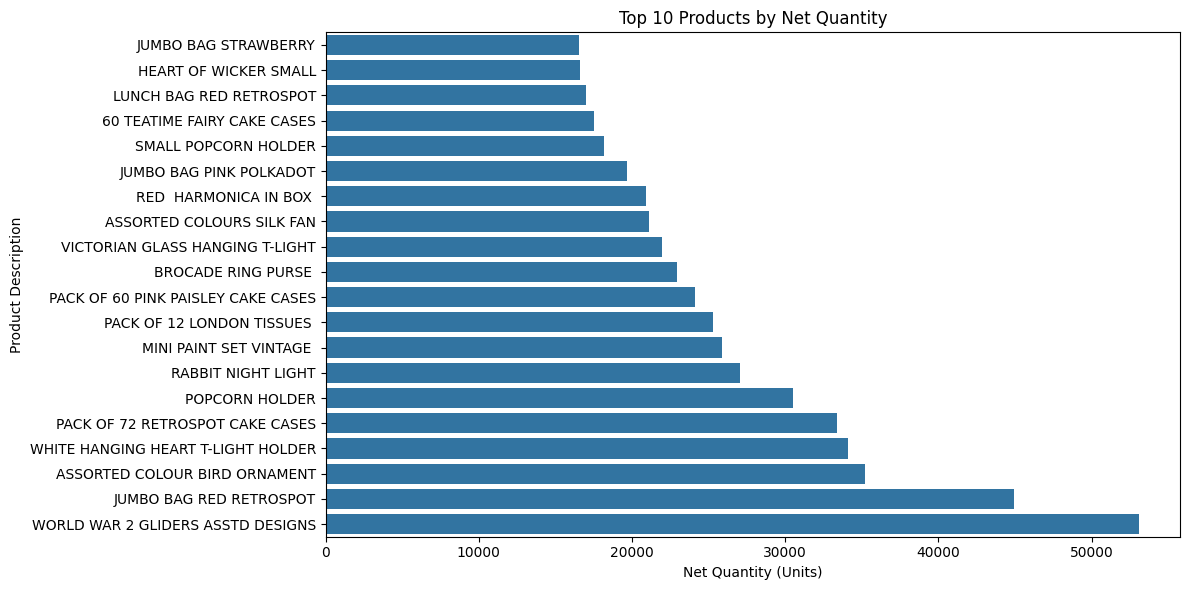

In [149]:
plot_data = top_net_sales.sort_values('Net Quantity')

plt.figure(figsize=(12, 6))

sns.barplot(
    x=plot_data['Net Quantity'],
    y=plot_data.index
)

plt.title('Top 10 Products by Net Quantity')
plt.xlabel('Net Quantity (Units)')
plt.ylabel('Product Description')

plt.tight_layout()
plt.show()

# تنصيف العملاء

In [119]:
customer_df = df.groupby('CustomerID').agg(
    Last_Purchase_Date=('InvoiceDate', 'max'),
    Total_Orders=('InvoiceNo', 'nunique'),
    Total_Spent=('LineTotal', 'sum'),
    Total_Items_Bought=('Quantity', 'sum')
).reset_index()

#أعلى العملاء إنفاقاً للمال

/tmp/ipykernel_2088/4134528609.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


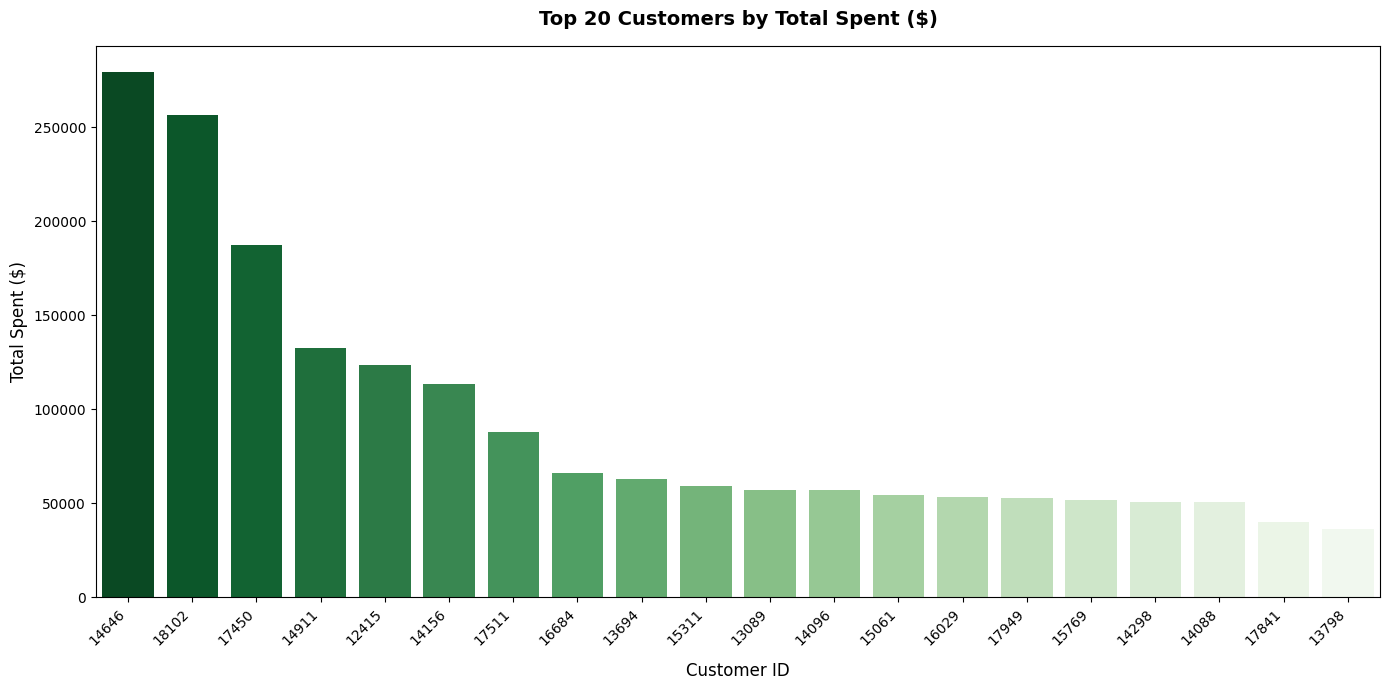

In [120]:
top_spent_customers = customer_df.sort_values(by='Total_Spent', ascending=False).head(20).copy()
top_spent_customers['CustomerID'] = top_spent_customers['CustomerID'].astype(str)

plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=top_spent_customers,
    x='CustomerID',
    y='Total_Spent',
    palette='Greens_r'
)

plt.title('Top 20 Customers by Total Spent ($)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Customer ID', fontsize=12, labelpad=10)
plt.ylabel('Total Spent ($)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

In [128]:
top_orders_customers = customer_df.sort_values(by='Total_Orders', ascending=False)
top_orders_customers.head(5)

,CustomerID,Last_Purchase_Date,Total_Orders,Total_Spent,Total_Items_Bought,Recency_Days,Avg_Order_Value,Customer_Segment
1894,14911,2011-12-08 15:54:00,248,132458.73,76905,0,534.107782,VIP / Champions
330,12748,2011-12-09 12:20:00,223,28405.56,23749,0,127.379193,VIP / Champions
4041,17841,2011-12-08 12:07:00,169,39869.05,22628,1,235.911538,VIP / Champions
1673,14606,2011-12-08 19:28:00,128,11633.35,5941,0,90.885547,VIP / Champions
568,13089,2011-12-07 09:02:00,118,57322.13,30742,2,485.780763,VIP / Champions


#أكثر العملاء تكراراً للطلبات

/tmp/ipykernel_2088/2569182974.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


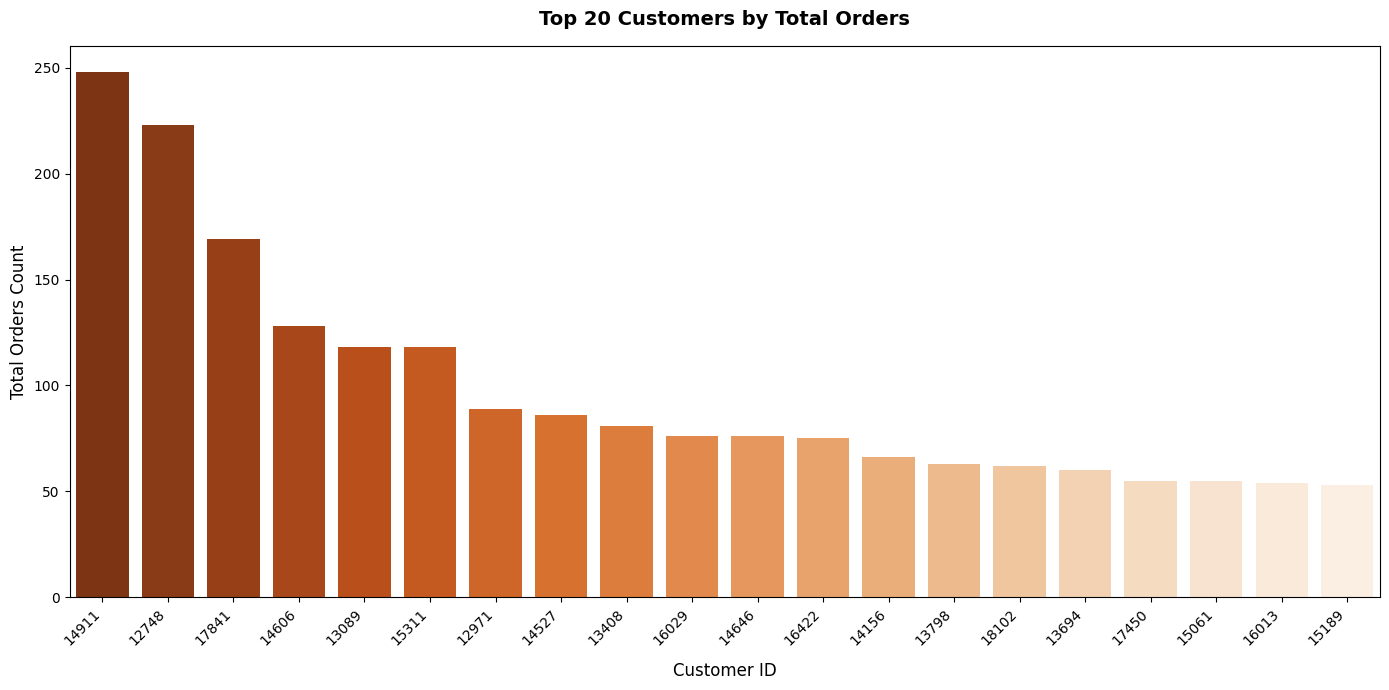

In [153]:
top_orders_customers = customer_df.sort_values(by='Total_Orders', ascending=False).head(20).copy()
top_orders_customers['CustomerID'] = top_orders_customers['CustomerID'].astype(str)

plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=top_orders_customers,
    x='CustomerID',
    y='Total_Orders',
    palette='Oranges_r'
)

plt.title('Top 20 Customers by Total Orders', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Customer ID', fontsize=12, labelpad=10)
plt.ylabel('Total Orders Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

In [127]:
top_items_customers = customer_df.sort_values(by='Total_Items_Bought', ascending=False)
top_items_customers.head(5)

,CustomerID,Last_Purchase_Date,Total_Orders,Total_Spent,Total_Items_Bought,Recency_Days,Avg_Order_Value,Customer_Segment
1702,14646,2011-12-08 12:12:00,76,279489.02,196143,1,3677.487105,VIP / Champions
55,12415,2011-11-15 14:22:00,26,123725.45,76946,23,4758.671154,VIP / Champions
1894,14911,2011-12-08 15:54:00,248,132458.73,76905,0,534.107782,VIP / Champions
3757,17450,2011-12-01 13:29:00,55,187322.17,69009,7,3405.857636,VIP / Champions
4232,18102,2011-12-09 11:50:00,62,256438.49,64122,0,4136.104677,VIP / Champions


#أكثر العملاء شراءً للقطع والكميات

/tmp/ipykernel_2088/1237073324.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


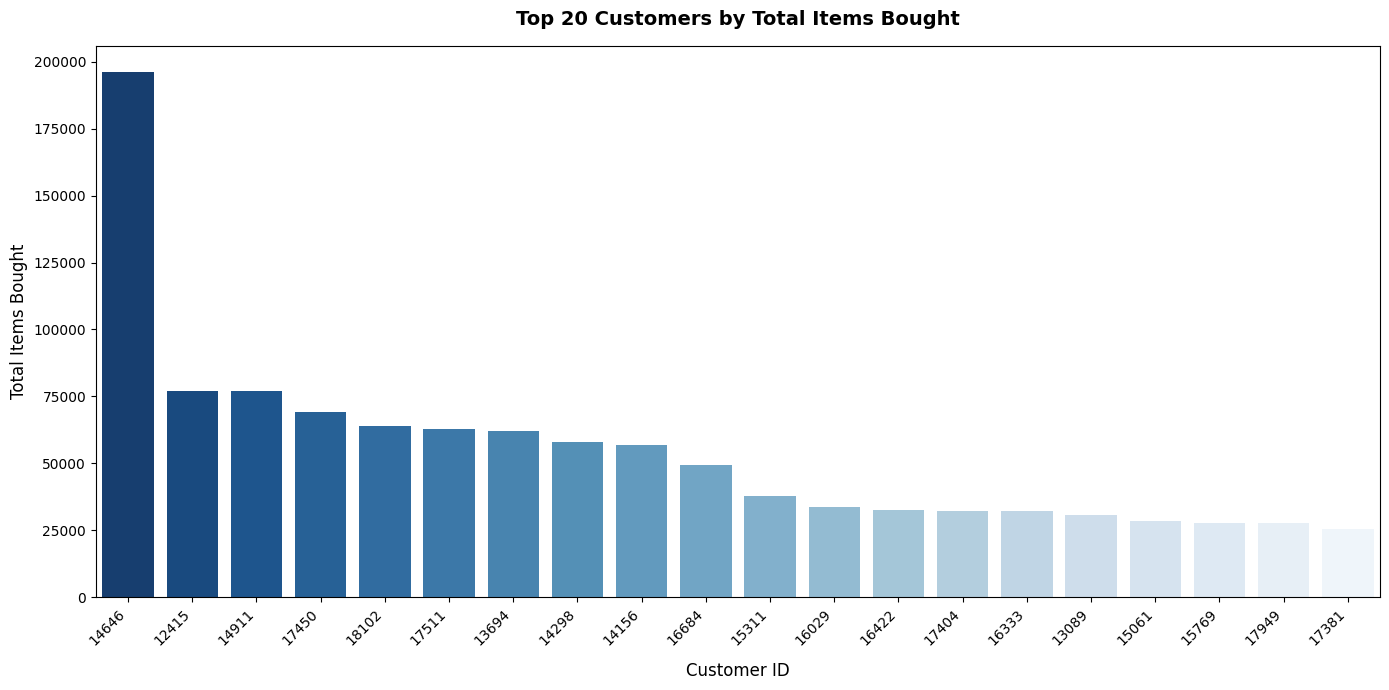

In [152]:

top_items_customers = customer_df.sort_values(by='Total_Items_Bought', ascending=False).head(20).copy()
top_items_customers['CustomerID'] = top_items_customers['CustomerID'].astype(str)

plt.figure(figsize=(14, 7))
ax = sns.barplot(
    data=top_items_customers,
    x='CustomerID',
    y='Total_Items_Bought',
    palette='Blues_r'
)

plt.title('Top 20 Customers by Total Items Bought', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Customer ID', fontsize=12, labelpad=10)
plt.ylabel('Total Items Bought', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()


plt.show()

In [125]:
max_date = df['InvoiceDate'].max()
customer_df['Recency_Days'] = (max_date - customer_df['Last_Purchase_Date']).dt.days


customer_df['Avg_Order_Value'] = customer_df['Total_Spent'] / customer_df['Total_Orders']
def segment_customer(row):
    if row['Total_Spent'] >= customer_df['Total_Spent'].quantile(0.8) and row['Recency_Days'] <= 30:
        return 'VIP / Champions'
    elif row['Total_Orders'] >= 5 and row['Recency_Days'] <= 60:
        return 'Loyal Customers'
    elif row['Recency_Days'] > 180:
        return 'At Risk / Lost'
    else:
        return 'Regular Customers'

customer_df['Customer_Segment'] = customer_df.apply(segment_customer, axis=1)


print(customer_df['Customer_Segment'].value_counts())

Customer_Segment
Regular Customers    2314
At Risk / Lost        862
VIP / Champions       631
Loyal Customers       564
Name: count, dtype: int64


# 5. Customer Value & RFM Analysis

The existing customer segmentation is useful as a first version. This section adds the three classic RFM dimensions:

- **Recency:** how recently the customer purchased.
- **Frequency:** how often the customer purchased.
- **Monetary:** how much the customer spent.

The goal is to connect each segment to a clear business action.


In [126]:
# RFM scores
rfm = customer_df[['CustomerID','Last_Purchase_Date','Total_Orders','Total_Spent']].copy()
rfm['Recency'] = (df['InvoiceDate'].max() - rfm['Last_Purchase_Date']).dt.days
rfm['Frequency'] = rfm['Total_Orders']
rfm['Monetary'] = rfm['Total_Spent']

# Higher score is better for all three dimensions; for Recency, fewer days is better.
rfm['R_Score'] = pd.qcut(rfm['Recency'].rank(method='first'), 5, labels=[5,4,3,2,1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1,2,3,4,5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), 5, labels=[1,2,3,4,5]).astype(int)
rfm['RFM_Score'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']

def rfm_segment(row):
    if row['RFM_Score'] >= 13:
        return 'Champions / VIP'
    elif row['RFM_Score'] >= 10:
        return 'Loyal / Potential Loyalist'
    elif row['RFM_Score'] >= 7:
        return 'Regular / Needs Attention'
    else:
        return 'At Risk / Lost'

rfm['RFM_Segment'] = rfm.apply(rfm_segment, axis=1)
rfm_summary = rfm['RFM_Segment'].value_counts().rename_axis('Segment').reset_index(name='Customers')
rfm_summary['Percentage'] = rfm_summary['Customers'] / rfm_summary['Customers'].sum() * 100
rfm_summary


,Segment,Customers,Percentage
0,At Risk / Lost,1322,30.244795
1,Regular / Needs Attention,1118,25.577671
2,Loyal / Potential Loyalist,988,22.603523
3,Champions / VIP,943,21.574011


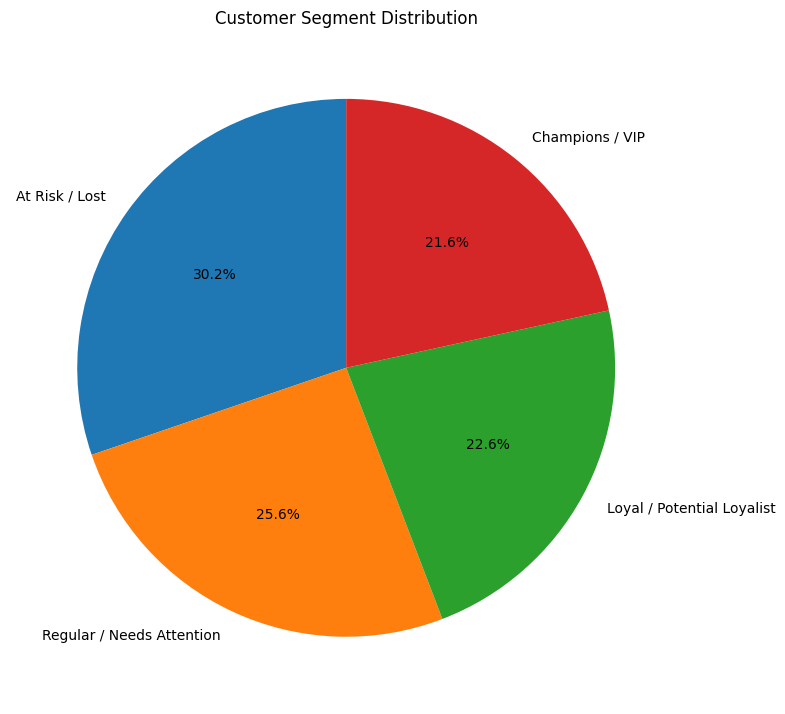

In [155]:
plt.figure(figsize=(8, 8))

plt.pie(
    rfm_summary['Customers'],
    labels=rfm_summary['Segment'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Segment Distribution')
plt.tight_layout()
plt.show()



## الاستنتاجات والتوصيات

### 1. التركيز على العملاء ذوي القيمة العالية (VIP & Loyal — 1,039 عميل)

يُنصح بالتركيز على الاحتفاظ بالعملاء ذوي القيمة العالية من خلال تقديم مزايا خاصة لهم، مثل الوصول المبكر للمنتجات الجديدة، وبرامج الولاء، والعروض الشخصية، مع ضمان توافر المنتجات التي يفضلونها.

كما يمكن استخدام بيانات هؤلاء العملاء، مع الالتزام بموافقات الخصوصية والتسويق، لبناء **جمهور مشابه (Lookalike Audience)** على منصات الإعلانات، بهدف الوصول إلى عملاء جدد لديهم سلوك مشابه لأفضل العملاء الحاليين.

### 2. إعادة تنشيط العملاء غير النشطين (At Risk / Lost — 858 عميل)

يوجد عدد كبير من العملاء المعرضين لفقدانهم أو الذين توقفوا عن الشراء. لذلك يمكن إطلاق حملات **Win-back** مخصصة عبر القنوات التي وافق العملاء على استقبال التسويق من خلالها.

ويمكن اختبار عدة عروض، مثل الخصومات أو الشحن المجاني، ومقارنة نتائجها لمعرفة العرض الأكثر تأثيرًا في إعادة العملاء للشراء.

### 3. زيادة متوسط قيمة الطلب للعملاء الاعتياديين (Regular Customers)

يمكن زيادة قيمة المشتريات من خلال استراتيجيات البيع الإضافي والبيع المتقاطع (**Upselling & Cross-selling**)، مثل:

* تقديم عروض على شراء أكثر من قطعة.
* إنشاء حزم منتجات (**Bundles**) تجمع المنتجات المرتبطة ببعضها.
* تقديم شحن مجاني عند تجاوز قيمة معينة للطلب.
* تطبيق عروض مثل: «اشترِ قطعتين واحصل على الثالثة بخصم 50%».

ويجب قياس تأثير هذه العروض على **متوسط قيمة الطلب (AOV)** وصافي المبيعات قبل تعميمها.

### 4. زيادة مخزون المنتجات الأكثر مبيعًا

يجب الحفاظ على مستوى مخزون مناسب من المنتجات الأكثر طلبًا، مع مراقبة حالات نفاد المخزون (**Stock-outs**) بشكل مستمر.

كما يجب الاهتمام بالعملاء الذين يشترون كميات كبيرة من منتج معين، والتأكد من توافر المنتج باستمرار والحفاظ على جودته، لأن عدم توفر المنتج أو انخفاض جودته قد يؤدي إلى خسارة فرص البيع والعملاء.

### 5. تحسين استراتيجية المنتجات الأكثر مبيعًا

بالنسبة للمنتجات التي تحقق أعلى المبيعات، لا يُفضل الاعتماد على زيادة الإنفاق الإعلاني عليها بشكل تلقائي إذا كان الطلب عليها مرتفعًا بالفعل.

يمكن دراسة توجيه جزء من الميزانية الإعلانية إلى المنتجات التي تحتاج إلى تنشيط مبيعاتها، مع الاستمرار في توفير المنتجات الأكثر مبيعًا بكميات كافية لتجنب نفاد المخزون وفقدان فرص البيع.

### 6. مراجعة المنتجات منخفضة المساهمة في المبيعات

يوجد **788 منتجًا منخفض المبيعات**، لذلك يُنصح بعدم اتخاذ قرار بإيقافها مباشرة، وإنما اختبار عدة استراتيجيات لتنشيط مبيعاتها، مثل:

* إطلاق حملات تسويقية وعروض ترويجية.
* تقديم خصومات مدروسة.
* استخدام **Product Bundling** وربط المنتجات منخفضة المبيعات بالمنتجات الأكثر مبيعًا.
* تحسين طريقة عرض المنتجات داخل المتجر.

وفي حالة استمرار انخفاض المبيعات، يمكن دراسة تقليل أو إيقاف إعادة طلب هذه المنتجات، خصوصًا إذا كانت تكاليف تخزينها مرتفعة مقارنة بمساهمتها في المبيعات.

### 7. تحليل صافي الكمية المباعة وتحديد المنتجات الأكثر طلبًا

أظهر تحليل صافي الكمية المباعة وجود منتجات تحقق كميات صافية مرتفعة مقارنةً بغيرها، مثل **WORLD WAR 2 GLIDERS ASSTD DESIGNS** و**JUMBO BAG RED RETROSPOT**.

يُنصح بالاستفادة من هذه النتائج في تخطيط المخزون وتحديد أولويات إعادة الطلب، مع مراعاة الكميات المباعة والمرتجعة لكل منتج، لضمان توافر المنتجات التي تحقق طلبًا مرتفعًا.

كما يُفضل ربط هذا التحليل بالإيرادات وتكاليف المنتجات لتقييم مساهمتها الفعلية في الأداء المالي للمتجر.

### 8. متابعة المرتجعات والإلغاءات وتحسين تجربة العملاء

يجب متابعة الكميات السالبة بشكل منفصل لأنها قد تشير إلى مرتجعات أو إلغاءات للفواتير.

فعلى سبيل المثال، سجل منتج **WHITE HANGING HEART T-LIGHT HOLDER** كمية مرتجعة بلغت 2,578 وحدة، بينما سجل منتج **ASSORTED COLOUR BIRD ORNAMENT** كمية مرتجعة بلغت 48 وحدة فقط.

تساعد هذه الفروق في تحديد المنتجات التي تستحق مزيدًا من المراجعة. لذلك يُنصح بتحليل بيانات المرتجعات والإلغاءات، والتحقق من أسبابها إذا كانت متاحة، ثم اتخاذ الإجراءات المناسبة لتحسين جودة المنتجات وتجربة العملاء وتقليل الخسائر المحتملة.

### الخلاصة

تساعد نتائج تحليل البيانات على اتخاذ قرارات أكثر دقة فيما يتعلق بإدارة العملاء، وتحسين المبيعات، وتخطيط المخزون، ومراجعة المنتجات منخفضة الأداء، ومتابعة المرتجعات والإلغاءات. ويُوصى بمتابعة مؤشرات الأداء الرئيسية بصورة دورية، مثل **صافي المبيعات، ومتوسط قيمة الطلب (AOV)، ومعدل الاحتفاظ بالعملاء، وصافي الكمية المباعة، ومعدل المرتجعات**، لقياس تأثير التوصيات وتحديد الاستراتيجيات الأكثر فاعلية.


---

## الخلاصة النهائية

يوضح التحليل رحلة متكاملة تبدأ من:

**تنظيف البيانات → تحليل المبيعات → تحليل المنتجات → تحليل سلوك العملاء → تقسيم العملاء → تقديم توصيات قابلة للتنفيذ.**

ولتحويل التحليل من مجرد قياس للمبيعات إلى **قرارات أكثر دقة وربحية**، يُنصح في المرحلة القادمة بدمج بيانات **التكاليف وهوامش الربح والمخزون والقنوات التسويقية**. سيساعد ذلك على تحديد المنتجات والعملاء والحملات التي تحقق أعلى **Profitability وROI**، وليس فقط أعلى مبيعات.
